# 1. Saúde da Mulher na África Subsaariana

Contracepção, pré-natal, assistência materno-infantil e desigualdades sociais: Quanto das diferenças rurais e urbanas se relacionam à riqueza e à escolaridade?

# 2. Equipe

Henrique Lima Gusmão (2025014508); 
Felipe Pires Franco (2025051411);
Izabella Galdino Correia (2025096601);
Alice Lina Oliveira da Silva (2025106933).

# 3. Descrição dos dados

--> Todos os scripts, dados e a aplicação para ver os dados traduzidos com o Python/Flask estão disponíveis no [GitHub](https://github.com/limag-henrique/subsaharanAfrica-womenData). 

### 3.1 Obtenção dos dados brutos

1. Acessamos o [DHS Program](https://dhsprogram.com/data/Access-Instructions.cfm), solicitamos acesso e baixamos os dados em arquivos ZIP;
2. Extraímos os arquivos Stata (.dta) e selecionamos as entrevistas femininas, histórico de nascimentos, domicílios, moradores, crianças menores de 5 anos e entrevistas masculinas/parceiros. 
3. Executamos os scripts de preparação e filtragem assistidos por IA, selecionamos as variáveis relevantes e convertemos os arquivos em CSV compactado (.csv.gz) para popular o banco SQLite e o banco relacional normalizado em 3FN.
4. Utilizamos a aplicação **Python/Flask** para traduzir e relacionar os códigos das variáveis e respostas aos seus significados em português e conferir se aqueles dados faziam sentido.

**Abaixo descrevo como que automatizei a quantificação dos dados:**

### Seleção das pesquisas e cobertura temporal

Para cada país, escolhe-se o arquivo IR de maior fase disponível entre os arquivos locais, ordenando a parte numérica e o sufixo da fase. O recorte inclui os 37 países do manifesto do projeto.

O ano da entrevista na base normalizada entregue é entre 1989~2025.


In [1]:
import subprocess
import sys
from pathlib import Path
from contextlib import closing
import sqlite3

for pacote in ("pandas", "matplotlib"):
    try:
        __import__(pacote)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

import pandas as pd
from IPython.display import display

DDL = """
CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
CREATE TABLE Domicilio(
  id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
  cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
  residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
  eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo','MR_sem_HR')),
  UNIQUE(levantamento_id,cluster,numero));
CREATE TABLE Mulher(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Parceiro(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  total_filhos INTEGER, idade_primeiro_filho INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Entrevista(
  mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
  data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
  coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
CREATE TABLE Nascimento(
  id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
  ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
  consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
  assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
CREATE TABLE Crianca(
  nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
  diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
CREATE TABLE Vacina_Remedio(
  id INTEGER PRIMARY KEY, codigo TEXT NOT NULL UNIQUE, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Crianca_Vacina(
  nascimento_id TEXT NOT NULL REFERENCES Crianca(nascimento_id),
  vacina_id INTEGER NOT NULL REFERENCES Vacina_Remedio(id),
  status_codigo INTEGER NOT NULL CHECK(status_codigo BETWEEN 0 AND 9),
  PRIMARY KEY(nascimento_id,vacina_id)) WITHOUT ROWID;
CREATE TABLE Morador(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Metodo(
  id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
CREATE TABLE Conhecimento_Metodo(
  mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
  nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;
"""
with closing(sqlite3.connect(":memory:")) as esquema:
    esquema.execute("PRAGMA foreign_keys=ON")
    esquema.executescript(DDL)
print("DDL executado - 13 relações com Chave Primária, Estrangeira, única e CHECK.")

DDL executado - 13 relações com Chave Primária, Estrangeira, única e CHECK.


In [2]:
import csv
import gzip
import sqlite3
from contextlib import closing
from pathlib import Path
from uuid import uuid4
import pandas as pd
from database_python.carregar_sqlite import manifest_rows, columns_for, PREFIX_COLUMNS
from database_python.relatorio_notebook import construir_banco

COLUNAS = {
    "IR": ["v001", "v002", "v003", "v024", "v025", "v190", "v012", "v106", "v201", "v212",
           "v006", "v007", "v008", "v005", "v312"] + [f"v304_{i:02d}" for i in range(1, 10)],
    "HR": ["hv001", "hv002", "hv024", "hv025", "hv270", "hv206", "hv201", "hv009"],
    "PR": ["hv001", "hv002", "hvidx", "hv104", "hv105", "hv106", "hv101"],
    "BR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "m3a", "m3b"],
    "KR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "b8", "h11", "h1",
           "h2", "h3", "h4", "h5", "h6", "h7", "h8", "h9"],
    "MR": ["mv001", "mv002", "mv003", "mv024", "mv025", "mv190", "mv012", "mv106", "mv201", "mv212"],
}
TABELAS_RECODE = dict(IR="Mulher", HR="Domicilio", PR="Morador", BR="Nascimento", KR="Crianca", MR="Parceiro")


def ler_csvs(dados, origem):
    """Lê CSVs gzip em lotes, alinhando as colunas de cada país pelo manifesto."""
    arquivo_esquemas = dados / "manifesto_selecao.csv"
    if not arquivo_esquemas.exists():
        arquivo_esquemas = dados.parent.parent / "docs/esquemas_csv.csv"
    manifesto = [m for m in manifest_rows(arquivo_esquemas) if m["recode"] in COLUNAS]
    origem.executescript("CREATE TABLE Pais(pais_codigo TEXT PRIMARY KEY, nome_pais TEXT); "
                        "CREATE TABLE Levantamento(levantamento_id TEXT PRIMARY KEY, pais_codigo TEXT, fase TEXT);")
    paises = {m["pais_codigo"]: m["pais_nome"] for m in manifesto}
    pesquisas = {(m["pais_codigo"], m["fase"]) for m in manifesto}
    origem.executemany("INSERT INTO Pais VALUES (?, ?)", paises.items())
    origem.executemany("INSERT INTO Levantamento VALUES (?, ?, ?)",
                       [(f"{pais}_{fase}", pais, fase) for pais, fase in sorted(pesquisas)])
    for recode, selecionadas in COLUNAS.items():
        itens = [m for m in manifesto if m["recode"] == recode]
        if not itens:
            raise ValueError(f"Recode obrigatório ausente no manifesto: {recode}")
        tabela = TABELAS_RECODE[recode]
        colunas = PREFIX_COLUMNS + selecionadas
        tipos = [f'"{c}" TEXT' for c in PREFIX_COLUMNS] + [f'"{c}" NUMERIC' for c in selecionadas]
        origem.execute(f"CREATE TABLE {tabela} ({', '.join(tipos)})")
        inserir = f"INSERT INTO {tabela} VALUES ({', '.join('?' for _ in colunas)})"
        with gzip.open(dados / f"{recode}.csv.gz", "rt", encoding="utf-8-sig", newline="") as arquivo:
            leitor = csv.reader(arquivo)
            if next(leitor, None) != columns_for(itens[0]):
                raise ValueError(f"Cabeçalho incompatível: {recode}")
            for item in itens:
                esquema = columns_for(item)
                posicoes = [esquema.index(c) if c in esquema else None for c in colunas]
                esperado = [item["pais_codigo"], item["pais_nome"],
                            f"{item['pais_codigo']}_{item['fase']}", item["fase"], item["arquivo_origem"]]
                lote = []
                for _ in range(int(item["linhas"])):
                    linha = next(leitor, None)
                    if linha is None or len(linha) != len(esquema) or linha[:5] != esperado:
                        raise ValueError(f"Linha incompatível com o manifesto: {recode}/{item['pais_codigo']}")
                    lote.append([linha[i] or None if i is not None else None for i in posicoes])
                    if len(lote) == 10000:
                        origem.executemany(inserir, lote)
                        lote.clear()
                origem.executemany(inserir, lote)
            if next(leitor, None) is not None:
                raise ValueError(f"Linhas excedentes: {recode}")
    origem.commit()


def verificar_banco(destino):
    """Retorna o resumo de um banco válido e populado; banco ausente/vazio exige carga."""
    if not destino.exists():
        return None
    with closing(sqlite3.connect(":memory:")) as esperado:
        esperado.executescript(DDL)
        definicoes = dict(esperado.execute("SELECT name, sql FROM sqlite_master WHERE type='table'"))
    with closing(sqlite3.connect(str(destino))) as banco:
        atual = dict(banco.execute("SELECT name, sql FROM sqlite_master WHERE type='table'"))
        if not definicoes.keys() <= atual.keys():
            return None
        if any(''.join(sql.split()).lower() != ''.join(atual[t].split()).lower() for t, sql in definicoes.items()):
            raise ValueError("Esquema existente incompatível com o DDL normalizado.")
        falhas = banco.execute("PRAGMA foreign_key_check").fetchall()
        if falhas:
            raise ValueError(f"Integridade referencial inválida: {falhas[:5]}")
        contagens = {t: banco.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in definicoes}
        obrigatorias = ["Pais", "Levantamento", "Domicilio", "Mulher", "Parceiro", "Entrevista",
                        "Nascimento", "Crianca", "Vacina_Remedio", "Crianca_Vacina", "Morador",
                        "Metodo", "Conhecimento_Metodo"]
        if any(contagens[t] == 0 for t in obrigatorias):
            return None
        return pd.DataFrame(contagens.items(), columns=["Tabela", "Registros"])


def preparar_banco(dados, destino, suplementos=()):
    """Reutiliza o banco válido ou carrega CSVs e publica o banco após a validação."""
    dados, destino = Path(dados).resolve(), Path(destino).resolve()
    if destino.name == "saude_mulher_dhs.db":
        raise ValueError("O banco de preparação não pode ser substituído pela carga normalizada.")
    resumo = verificar_banco(destino)
    if resumo is not None:
        resumo.attrs["acao"] = "reutilizado"
        return resumo
    temporario = destino.with_name(f".carga_dhs_{uuid4().hex}.db")
    try:
        with closing(sqlite3.connect(str(temporario))) as origem:
            ler_csvs(dados, origem)
        construir_banco(temporario, destino, suplementos, ddl=DDL)
    finally:
        temporario.unlink(missing_ok=True)
    resumo = verificar_banco(destino)
    if resumo is None:
        raise ValueError("Carga concluída sem os registros essenciais.")
    resumo.attrs["acao"] = "criado"
    return resumo

In [3]:
from pathlib import Path
from IPython.display import display

raiz = Path.cwd()
resumo_banco = preparar_banco(raiz / "dados/relevantes", raiz / "saude_mulher_normalizado.db")
print(f"Banco {resumo_banco.attrs['acao']}; integridade referencial validada nas 13 tabelas.")
display(resumo_banco)

,Tabela,Registros
0,Pais,37
1,Levantamento,114
2,Domicilio,567348
3,Mulher,584004
4,Parceiro,236070
5,Entrevista,584004
6,Nascimento,930745
7,Crianca,282641
8,Vacina_Remedio,8
9,Crianca_Vacina,1174167


Banco reutilizado; integridade referencial validada nas 13 tabelas.


**Coloco a entidade, o valor bruto e a base normalizada com as pesquisas complementares fora do escopo principal:**
- Mulheres/entrevistas, 407.600, 584.004
- Domicílios, 385.457, 567.348
- Nascimentos, 877.412. 930.745

O núcleo abrange 37 países, 1.884.683 moradores, 282.641 crianças menores de 5 anos e 236.070 parceiros/homens entrevistados. A ampliação acrescenta 176.404 entrevistas suplementares.


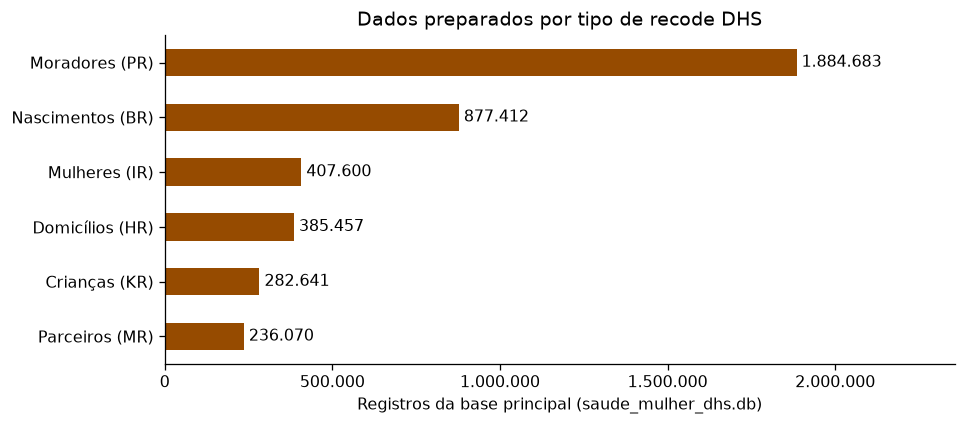

In [1]:
from pathlib import Path
from contextlib import closing
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

raiz = Path.cwd()
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 115})
azul = "#964B00"

def exibir(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

with closing(sqlite3.connect(str(raiz / "saude_mulher_dhs.db"))) as banco:
    tipos = {
        "Mulher": "Mulheres (IR)",
        "Nascimento": "Nascimentos (BR)",
        "Domicilio": "Domicílios (HR)",
        "Morador": "Moradores (PR)",
        "Crianca": "Crianças (KR)",
        "Parceiro": "Parceiros (MR)",
    }
    registros = pd.Series({nome: banco.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
                           for tabela, nome in tipos.items()})
    residencia = pd.read_sql_query("""
        SELECT v025 AS residencia, COUNT(*) AS entrevistas
        FROM Mulher GROUP BY v025
    """, banco)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
registros.sort_values().plot.barh(ax=ax, color=azul)
ax.set(xlabel="Registros da base principal (saude_mulher_dhs.db)", title="Dados preparados por tipo de recode DHS",
       xlim=(0, registros.max() * 1.25))
for y, valor in enumerate(registros.sort_values()):
    ax.text(valor, y, " " + f"{valor:,}".replace(",", "."), va="center")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
exibir(fig)

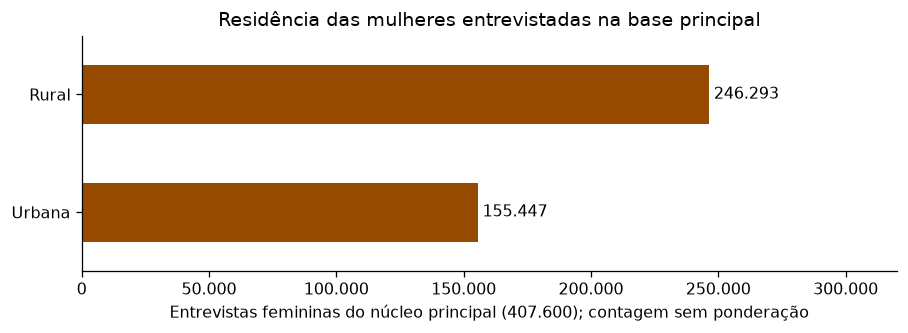

Residência sem informação válida no núcleo principal (Sudão): 5.860 entrevistas.


In [2]:
contagens = residencia.set_index("residencia").entrevistas.reindex([1, 2], fill_value=0)
contagens.index = ["Urbana", "Rural"]
sem_informacao = int(residencia.entrevistas.sum() - contagens.sum())
fig, ax = plt.subplots(figsize=(8, 3))
contagens.plot.barh(ax=ax, color=azul)
ax.set(xlabel="Entrevistas femininas do núcleo principal (407.600); contagem sem ponderação",
       title="Residência das mulheres entrevistadas na base principal", xlim=(0, contagens.max() * 1.3))
for y, valor in enumerate(contagens):
    ax.text(valor, y, " " + f"{valor:,}".replace(",", "."), va="center")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
exibir(fig)
print(f"Residência sem informação válida no núcleo principal (Sudão): {sem_informacao:,} entrevistas.".replace(",", "."))

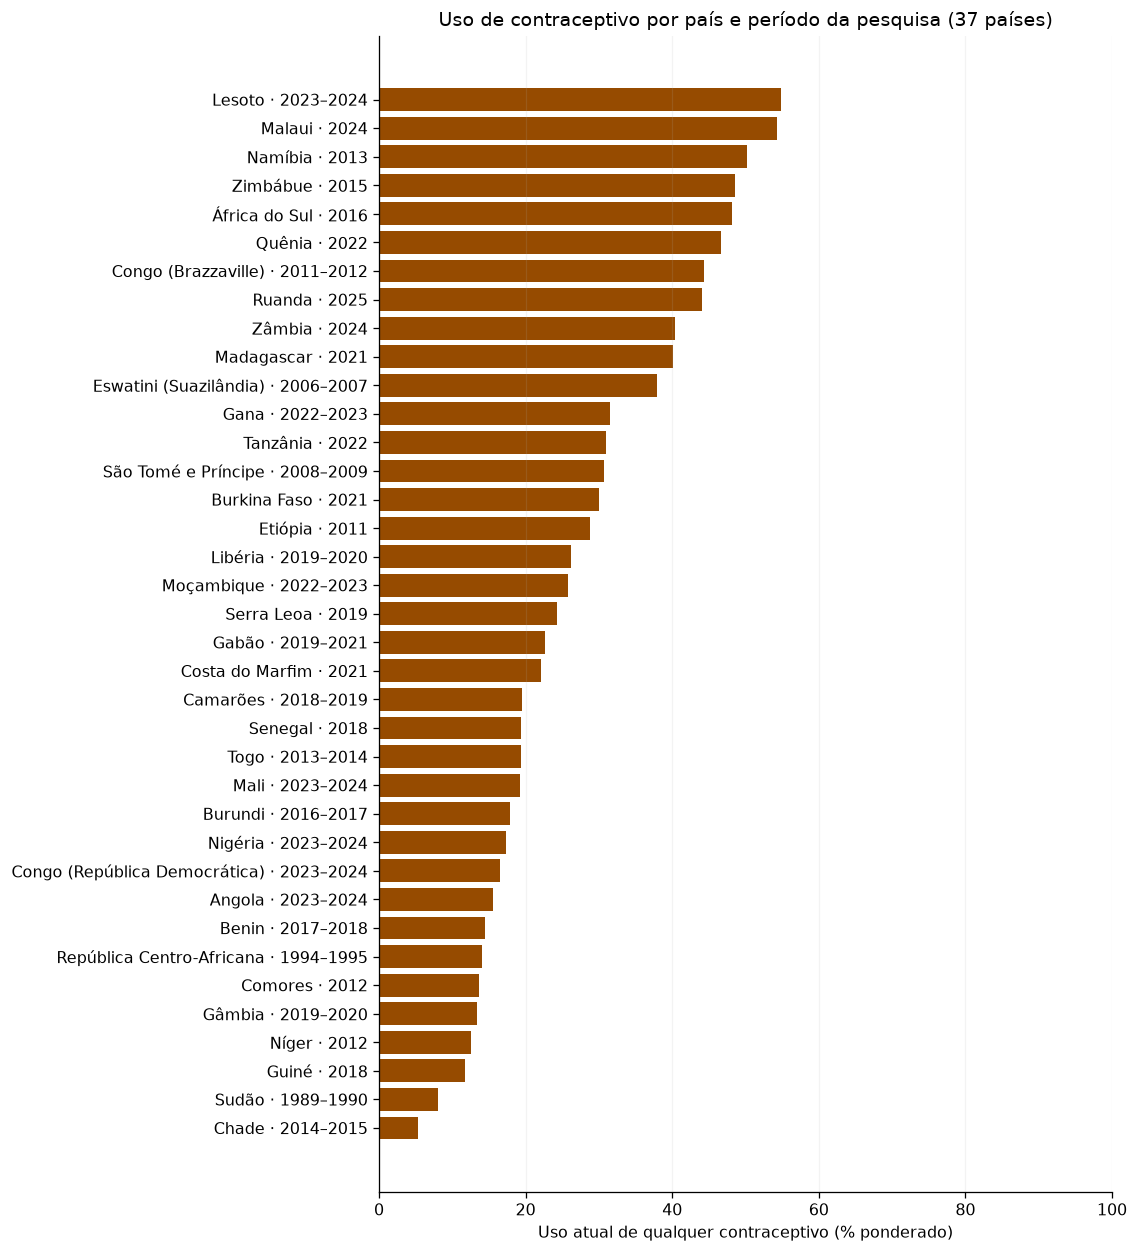

In [3]:
with closing(sqlite3.connect(str(raiz / "saude_mulher_normalizado.db"))) as banco:
    contracepcao = pd.read_sql_query("""
        SELECT p.codigo, p.nome, MIN(e.ano) AS inicio, MAX(e.ano) AS fim,
               ROUND(100.0 * SUM(e.peso * e.usa_metodo) / SUM(e.peso), 2) AS uso_percentual
        FROM Entrevista e
        JOIN Mulher m ON m.id = e.mulher_id
        JOIN Domicilio d ON d.id = m.domicilio_id
        JOIN Levantamento l ON l.id = d.levantamento_id
        JOIN Pais p ON p.codigo = l.pais_codigo
        WHERE e.coorte != 'nucleo_exclusivo' AND e.usa_metodo IS NOT NULL AND e.peso > 0
        GROUP BY p.codigo, p.nome
    """, banco).sort_values("uso_percentual")

periodos = contracepcao.apply(lambda r: str(int(r.inicio)) if r.inicio == r.fim
                              else f"{int(r.inicio)}–{int(r.fim)}", axis=1)
rotulos = contracepcao.nome + " · " + periodos
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(rotulos, contracepcao.uso_percentual, color=azul)
ax.set(xlim=(0, 100), xlabel="Uso atual de qualquer contraceptivo (% ponderado)",
       title="Uso de contraceptivo por país e período da pesquisa (37 países)")
ax.grid(axis="x", alpha=.15)
exibir(fig)

In [4]:
from pathlib import Path
from time import perf_counter
from statistics import median
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from database_python.relatorio_notebook import (
    abrir_banco, sha256, consultar, detalhes, mostrar, barras, mapa, pares,
    AZUL, LARANJA,
)

conn, origem, hash_origem = abrir_banco(Path.cwd())
nomes = dict(conn.execute("SELECT codigo, nome FROM Pais"))

def consulta(sql, amostra=False):
    return consultar(conn, sql, amostra)

def nomear(df):
    return df.rename(index=nomes).sort_index()

cobertura = consulta("""
SELECT p.codigo, p.nome, l.fase, e.coorte, MIN(e.ano) AS ano_min, MAX(e.ano) AS ano_max,
       COUNT(*) AS mulheres,
       SUM(e.usa_metodo IS NOT NULL) AS resposta_contraceptiva,
       SUM(d.riqueza IS NOT NULL) AS riqueza_disponivel,
       SUM(d.origem='HR') AS mulheres_com_HR
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
GROUP BY p.codigo, p.nome, l.fase, e.coorte
ORDER BY p.nome
""")
assert cobertura.codigo.nunique() == 37
assert len(cobertura) == 47

panorama = consulta("""
SELECT p.codigo, p.nome, l.fase, MIN(e.ano) AS ano_min, MAX(e.ano) AS ano_max,
       COUNT(*) AS entrevistas, SUM(e.usa_metodo IS NOT NULL AND e.peso > 0) AS respostas_validas,
       ROUND(100.0 * SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso > 0 THEN e.peso * e.usa_metodo END) /
       NULLIF(SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso > 0 THEN e.peso END), 0), 2) AS uso_percentual
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE e.coorte != 'nucleo_exclusivo'
GROUP BY p.codigo, p.nome, l.fase
ORDER BY p.nome
""")
assert len(panorama) == 37 and panorama.uso_percentual.notna().all()
print(f"Cobertura validada: {cobertura.mulheres.sum():,} entrevistas totais em 47 coortes ({cobertura.codigo.nunique()} países); recorte temático de contracepção com {panorama.entrevistas.sum():,} entrevistas.".replace(",", "."))

codigo,nome,fase,coorte,ano_min,ano_max,mulheres,resposta_contraceptiva,riqueza_disponivel,mulheres_com_HR
AO,Angola,81,nucleo_e_contracepcao,2023,2024,14717,14717,14717,14717
BJ,Benin,71,nucleo_e_contracepcao,2017,2018,15928,15928,15928,15928
BF,Burkina Faso,81,nucleo_e_contracepcao,2021,2021,17659,17659,17659,17659
BU,Burundi,71,nucleo_e_contracepcao,2016,2017,17269,17269,17269,17269
CM,Camarões,71,contracepcao,2018,2019,14677,13527,14677,0
CM,Camarões,82,nucleo_exclusivo,2022,2022,6532,0,6532,6532
TD,Chade,71,nucleo_e_contracepcao,2014,2015,17719,17719,17719,17719
KM,Comores,61,nucleo_e_contracepcao,2012,2012,5329,5329,5329,5329
CG,Congo (Brazzaville),61,nucleo_e_contracepcao,2011,2012,10819,10819,10819,10819
CD,Congo (República Democrática),81,nucleo_e_contracepcao,2023,2024,27583,27583,27583,27583


codigo,nome,fase,ano_min,ano_max,entrevistas,respostas_validas,uso_percentual
AO,Angola,81,2023,2024,14717,14717,15.58
BJ,Benin,71,2017,2018,15928,15928,14.41
BF,Burkina Faso,81,2021,2021,17659,17659,30.06
BU,Burundi,71,2016,2017,17269,17269,17.89
CM,Camarões,71,2018,2019,14677,13527,19.52
TD,Chade,71,2014,2015,17719,17719,5.35
KM,Comores,61,2012,2012,5329,5329,13.66
CG,Congo (Brazzaville),61,2011,2012,10819,10819,44.34
CD,Congo (República Democrática),81,2023,2024,27583,27583,16.55
CI,Costa do Marfim,81,2021,2021,14877,14877,22.05


Cobertura validada: 584.004 entrevistas totais em 47 coortes (37 países); recorte temático de contracepção com 510.884 entrevistas.


### 3.2 Dados processados e Reprodutibilidade

Pesquisamos a saúde da mulher na África Subsaariana, com foco em contracepção, pré-natal, assistência ao parto, vacinação infantil, contexto intradomiciliar e diferenças de residência, riqueza e escolaridade. A base principal contém 407.600 entrevistas femininas de 37 nações. 

Arquivos brutos que podem ser consultados no [GitHub](https://github.com/limag-henrique/subsaharanAfrica-womenData):
- IR.csv.gz (Mulher, Entrevista, Conhecimento_Metodo), com Idade, escolaridade, parturição, entrevista, pesos amostrais e conhecimento/uso de métodos contraceptivos
- BR.csv.gz (Nascimento), com Histórico de nascimentos, consultas de pré-natal, local do parto, cesárea e assistência médica/enfermagem 
- HR.csv.gz (Domicilio), com Moradia (urbana/rural), quintil de riqueza, eletricidade, fonte de água e total de membros 
- PR.csv.gz (Morador), com Composição familiar, sexo, idade, escolaridade e relação com o chefe do domicílio 
- KR.csv.gz (Crianca, Crianca_Vacina), com Crianças menores de 5 anos, diarreia recente, cartão de vacina e histórico das 8 vacinas
- MR.csv.gz (Parceiro), com Homens/parceiros entrevistados no domicílio: idade, escolaridade, total de filhos e idade ao primeiro filho 

Para reconstruir a versão ampliada, são necessários os CSVs zipados, o esquema, os scripts e os dez arquivos Stata do manifesto de contracepção (todos já no GitHub). Use o script abaixo para executar a reconstrução. 

```python
import json
from pathlib import Path

raiz = Path.cwd()
manifesto = json.loads(
    (raiz / "docs/manifesto_contracepcao.json").read_text(encoding="utf-8")
)
# Extraia previamente os dez arquivos nesta pasta, preservando seus nomes.
pasta = raiz / "dados/completo/extraidos"
suplementos = []
for item in manifesto:
    candidatos = [p for p in pasta.rglob("*")
                  if p.is_file() and p.name.casefold() == item["arquivo_origem"].casefold()]
    if len(candidatos) != 1:
        raise FileNotFoundError(f"Esperado um arquivo para {item['arquivo_origem']}")
    suplementos.append(dict(item, caminho_origem=str(candidatos[0])))

destino = raiz / "saude_mulher_reconstruido.db"
if destino.exists():
    raise FileExistsError("Escolha um destino novo para verificar a reconstrução.")
resumo = preparar_banco(raiz / "dados/relevantes", destino, suplementos=suplementos)
display(resumo)
```


# 4. Diagrama ER

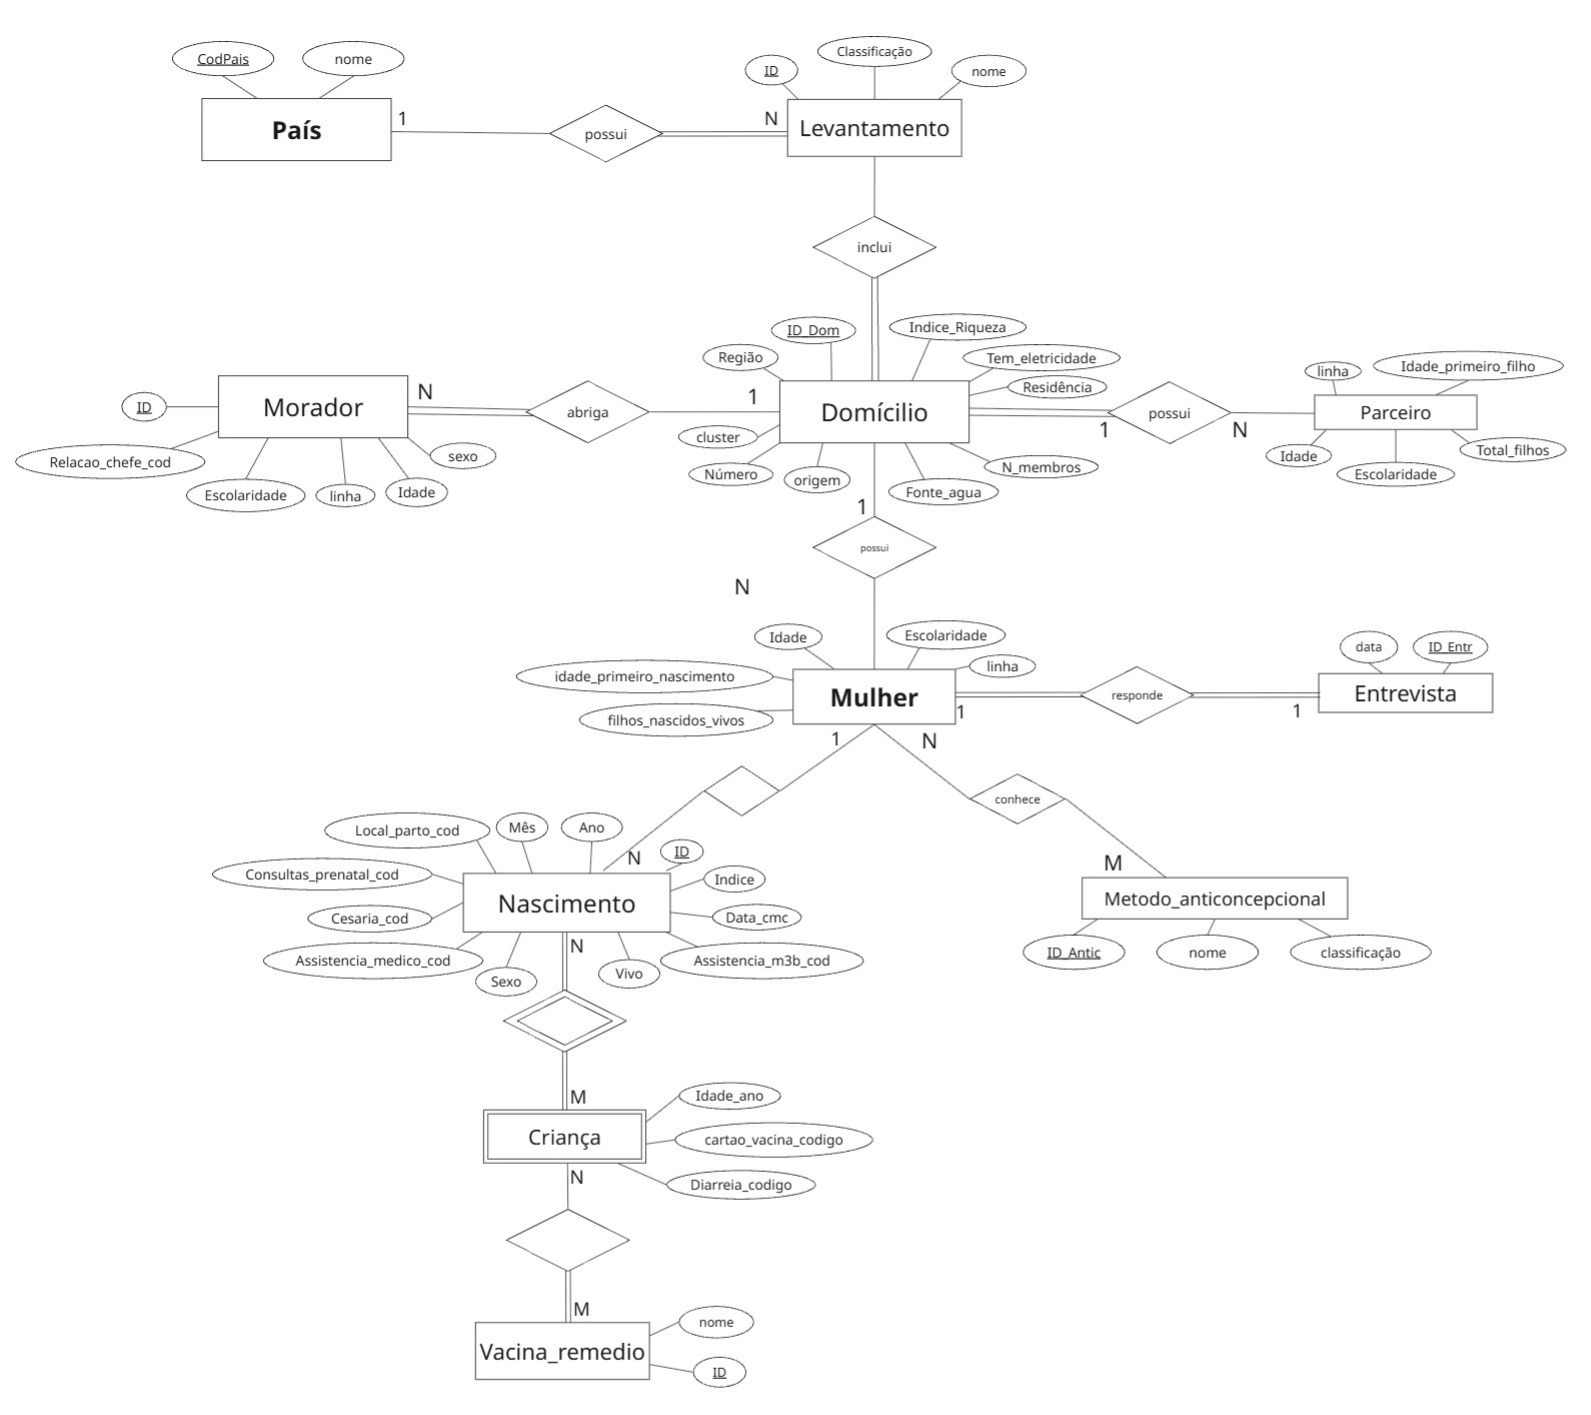

# 5. Diagrama relacional

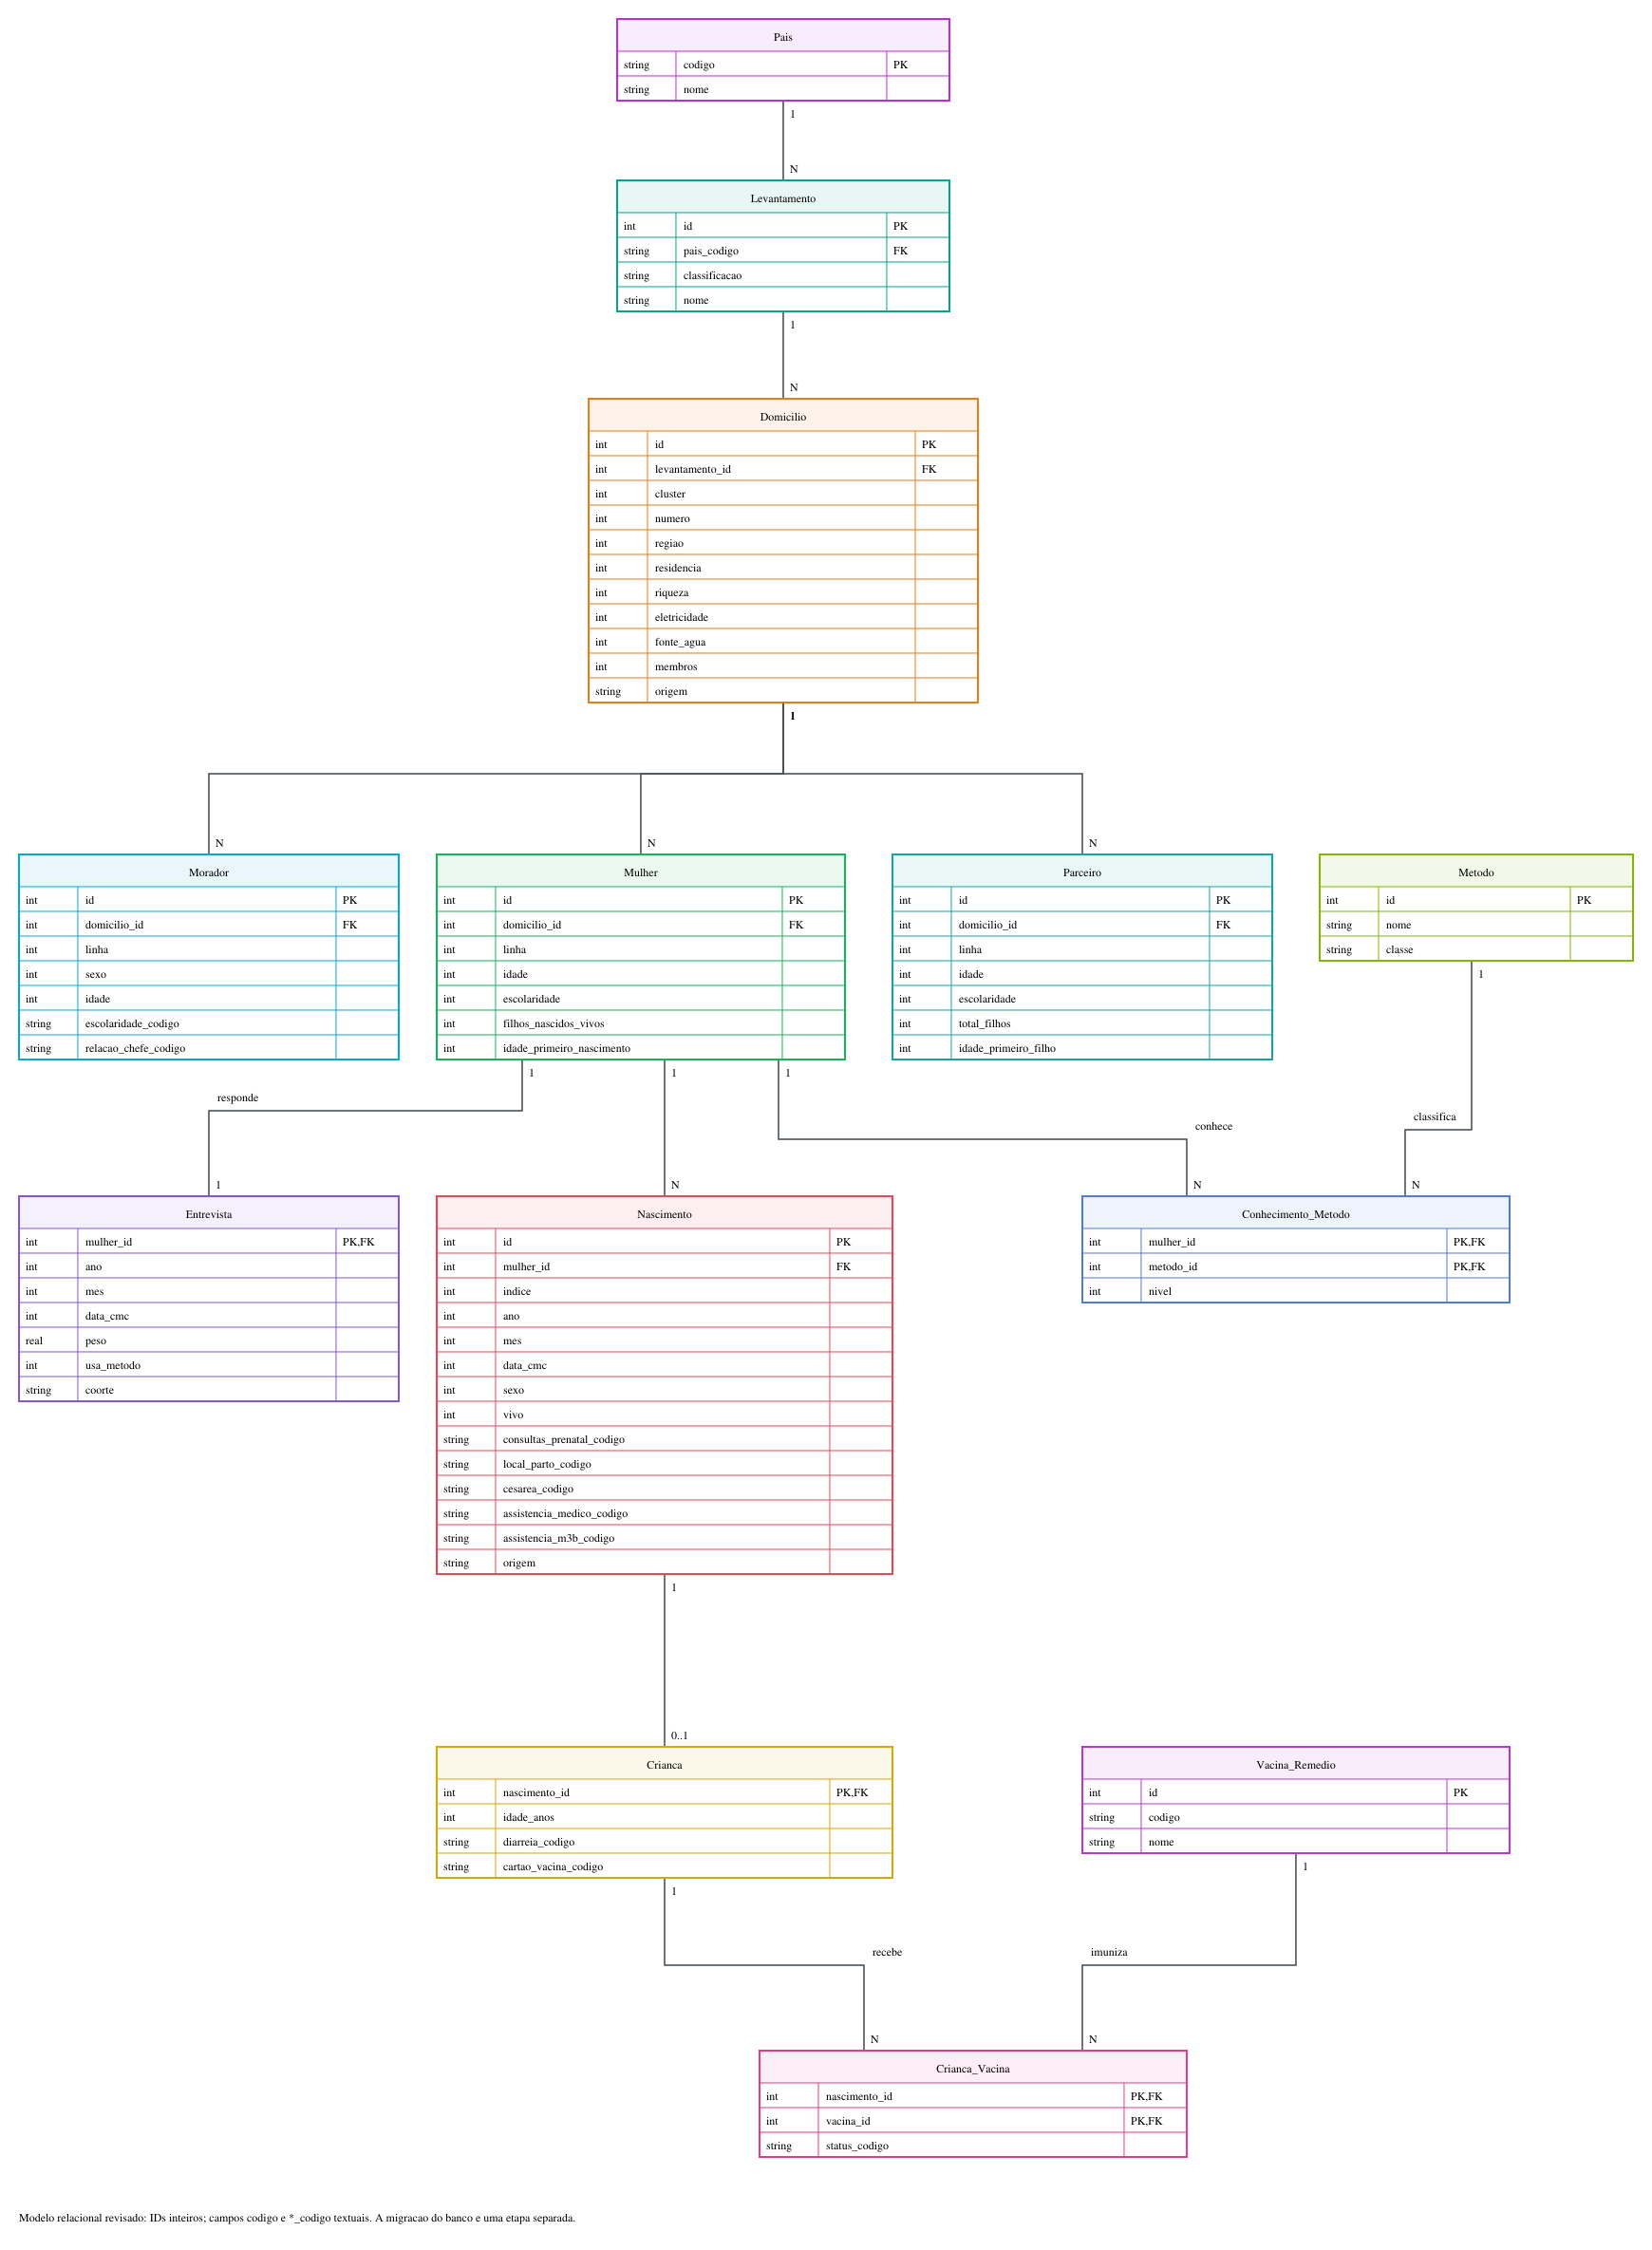

Pais(codigo, nome) PK: codigo

Levantamento(id, pais_codigo*, classificacao, nome) PK: id, FK: pais_codigo --> Pais(codigo)

Domicilio(id, levantamento_id*, cluster, numero, regiao, residencia, riqueza, eletricidade, fonte_agua, membros, origem) PK: id , FK: levantamento_id --> Levantamento(id)

Morador(id, domicilio_id*, linha, sexo, idade, escolaridade_codigo, relacao_chefe_codigo) PK: id, FK: domicilio_id --> Domicilio(id)

Mulher(id, domicilio_id*, linha, idade, escolaridade, filhos_nascidos_vivos, idade_primeiro_nascimento) PK: id, FK: domicilio_id --> Domicilio(id)

Parceiro(id, domicilio_id*, linha, idade, escolaridade, total_filhos, idade_primeiro_filho) PK: id, FK: domicilio_id --> Domicilio(id)

Entrevista(mulher_id*, ano, mes, data_cmc, peso, usa_metodo, coorte) PK: mulher_id, FK: mulher_id --> Mulher(id)

Nascimento(id, mulher_id*, indice, ano, mes, data_cmc, sexo, vivo, consultas_prenatal_codigo, local_parto_codigo, cesarea_codigo, assistencia_medico_codigo, assistencia_m3b_codigo, origem) PK: id, FK: mulher_id --> Mulher(id)

Crianca(nascimento_id*, idade_anos, diarreia_codigo, cartao_vacina_codigo) PK: nascimento_id, FK: nascimento_id --> Nascimento(id)
Vacina_Remedio (id, codigo, nome) PK: id

Crianca_Vacina(nascimento_id*, vacina_id*, status_codigo) PK: (nascimento_id, vacina_id), FK: nascimento_id --> Crianca(nascimento_id), vacina_id --> Vacina_Remedio(id)

Metodo(id, nome, classe) PK: id

Conhecimento_Metodo(mulher_id*, metodo_id*, nivel) PK: (mulher_id, metodo_id), FK: mulher_id --> Mulher(id), metodo_id --> Metodo(id)
### Convenção de tipos do modelo relacional revisado

- Identificadores `id` e referências terminadas em `_id` são `INTEGER` (`int` no diagrama), inclusive as chaves das tabelas associativas.
- Códigos `codigo`, `pais_codigo` e atributos terminados em `_codigo` são `TEXT` (`string` no diagrama). `Pais.codigo` continua sendo uma chave textual, pois identifica o código do país.
- `Levantamento.classificacao` substitui `fase` na representação relacional e `Levantamento.nome` é acrescentado como `TEXT`. A referência `pais_codigo` liga cada levantamento ao país.

**Estado da implementação:** esta revisão descreve o modelo solicitado. O DDL e a carga atuais ainda usam `fase`, não possuem `Levantamento.nome` e formam algumas chaves como textos compostos. A adoção de IDs inteiros exige uma migração com mapeamento das chaves e atualização de suas referências; trocar somente a indicação de tipo não converte o banco existente.


# 6. Consultas



# 7. Autoavaliação dos membros

- **Henrique Lima Gusmão** - Sugestão de datasets; Solicitação de dados à agência americana; Plano de proposta da saúde da mulher africana; Importação dos 9GB de dados; Filtragem e normalização dos dados referentes às mulheres, domicílios, moradores, crianças e parceiros; Criação de repositório; Criação do Python/Flask para análise visual dos dados; Tradução dos códigos para os respectivos nomes das entidades; Seções Descrição e Inovação Social da primeira proposta; Descrição, Manipulação de dados, Consultas SQL, Otimização e Diagrama Relacional alinhado ao Diagrama ER.

- **Felipe Pires Franco** - 

- **Izabella Galdino Correia** - 

- **Alice Lina Oliveira da Silva** - 

# 8. Declaração de Uso de Inteligência Artificial

Nesta seção, declaramos como ferramentas de Inteligência Artificial (IA) foram utilizadas durante o desenvolvimento deste trabalho.

### Ferramentas e finalidades de uso

- **ChatGPT Sol 6.1 Alto, no Codex**: Para a criação do visualizador Python/Flask e automação da correlação dos códigos dos atributos ao inglês e tradução ao português; Correção pontual de erros nos códigos SQL.
- **Gemini 3.8 Flash no Antigravity**: Para a instalação de pacotes necessários para testar o notebook, verificação de alinhamento das tabelas do banco SQLite ao Diagrama ER.

### O que não foi feito com IA

Análise crítica/qualitativa do significado destes dados, primeiras versões dos códigos SQL e escolha dos territórios, evitando assim possíveis vieses analíticos. Os autores assumem inteira responsabilidade por este conteúdo, considerando que todos os códigos foram testados, conferidos e modificados a critério da pesquisa quando necessário.